In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import linear_model

In [2]:
eth = pd.read_csv('data/coin_Ethereum.csv')
eth = eth.drop(['SNo', 'Name', 'Volume', 'Marketcap'], axis=1)
eth['Date'] = pd.to_datetime(eth['Date'])

eth_painel = eth.set_index(['Symbol', 'Date']).copy()
eth_painel

High          Low         Open        Close
Symbol Date                                                                   
ETH    2015-08-08 23:59:59     2.798810     0.714725     2.793760     0.753325
       2015-08-09 23:59:59     0.879810     0.629191     0.706136     0.701897
       2015-08-10 23:59:59     0.729854     0.636546     0.713989     0.708448
       2015-08-11 23:59:59     1.131410     0.663235     0.708087     1.067860
       2015-08-12 23:59:59     1.289940     0.883608     1.058750     1.217440
...                                 ...          ...          ...          ...
       2021-07-02 23:59:59  2155.596496  2021.824808  2109.892677  2150.040364
       2021-07-03 23:59:59  2237.567155  2117.590013  2150.835025  2226.114282
       2021-07-04 23:59:59  2384.286857  2190.837703  2226.550382  2321.724112
       2021-07-05 23:59:59  2321.922836  2163.041394  2321.922836  2198.582464
       2021-07-06 23:59:59  2346.294874  2197.919385  2197.919385  2324.679449

[2160 rows x 4 columns]

In [3]:
eth_painel['Retorno'] = eth_painel['Close'].pct_change()
eth_painel

High          Low         Open  \
Symbol Date                                                         
ETH    2015-08-08 23:59:59     2.798810     0.714725     2.793760   
       2015-08-09 23:59:59     0.879810     0.629191     0.706136   
       2015-08-10 23:59:59     0.729854     0.636546     0.713989   
       2015-08-11 23:59:59     1.131410     0.663235     0.708087   
       2015-08-12 23:59:59     1.289940     0.883608     1.058750   
...                                 ...          ...          ...   
       2021-07-02 23:59:59  2155.596496  2021.824808  2109.892677   
       2021-07-03 23:59:59  2237.567155  2117.590013  2150.835025   
       2021-07-04 23:59:59  2384.286857  2190.837703  2226.550382   
       2021-07-05 23:59:59  2321.922836  2163.041394  2321.922836   
       2021-07-06 23:59:59  2346.294874  2197.919385  2197.919385   

                                  Close   Retorno  
Symbol Date                                        
ETH    2015-08-08 23:59:59     0.753325       NaN  
       2015-08-09 23:59:59     0.701897 -0.068268  
       2015-08-10 23:59:59     0.708448  0.009333  
       2015-08-11 23:59:59     1.067860  0.507323  
       2015-08-12 23:59:59     1.217440  0.140075  
...                                 ...       ...  
       2021-07-02 23:59:59  2150.040364  0.017238  
       2021-07-03 23:59:59  2226.114282  0.035383  
       2021-07-04 23:59:59  2321.724112  0.042949  
       2021-07-05 23:59:59  2198.582464 -0.053039  
       2021-07-06 23:59:59  2324.679449  0.057354  

[2160 rows x 5 columns]

In [4]:
btc = pd.read_csv('data/coin_Bitcoin.csv')
btc = btc.drop(['SNo', 'Name', 'Volume', 'Marketcap'], axis=1)
btc['Date'] = pd.to_datetime(btc['Date'])

filtro = btc['Date'] >= eth['Date'].min()
btc = btc[filtro]

btc_painel = btc.set_index(['Symbol', 'Date']).copy()
btc_painel

High           Low          Open  \
Symbol Date                                                            
BTC    2015-08-08 23:59:59    279.928009    260.709991    279.742004   
       2015-08-09 23:59:59    267.002991    260.467987    261.115997   
       2015-08-10 23:59:59    267.032013    262.596008    265.477997   
       2015-08-11 23:59:59    270.385986    264.093994    264.342010   
       2015-08-12 23:59:59    270.673004    265.468994    270.597992   
...                                  ...           ...           ...   
       2021-07-02 23:59:59  33939.588699  32770.680780  33549.600177   
       2021-07-03 23:59:59  34909.259899  33402.696536  33854.421362   
       2021-07-04 23:59:59  35937.567147  34396.477458  34665.564866   
       2021-07-05 23:59:59  35284.344430  33213.661034  35284.344430   
       2021-07-06 23:59:59  35038.536363  33599.916169  33723.509655   

                                   Close  
Symbol Date                               
BTC    2015-08-08 23:59:59    260.997009  
       2015-08-09 23:59:59    265.083008  
       2015-08-10 23:59:59    264.470001  
       2015-08-11 23:59:59    270.385986  
       2015-08-12 23:59:59    266.376007  
...                                  ...  
       2021-07-02 23:59:59  33897.048590  
       2021-07-03 23:59:59  34668.548402  
       2021-07-04 23:59:59  35287.779766  
       2021-07-05 23:59:59  33746.002456  
       2021-07-06 23:59:59  34235.193451  

[2160 rows x 4 columns]

In [5]:
btc_painel['Retorno'] = btc_painel['Close'].pct_change()
btc_painel

High           Low          Open  \
Symbol Date                                                            
BTC    2015-08-08 23:59:59    279.928009    260.709991    279.742004   
       2015-08-09 23:59:59    267.002991    260.467987    261.115997   
       2015-08-10 23:59:59    267.032013    262.596008    265.477997   
       2015-08-11 23:59:59    270.385986    264.093994    264.342010   
       2015-08-12 23:59:59    270.673004    265.468994    270.597992   
...                                  ...           ...           ...   
       2021-07-02 23:59:59  33939.588699  32770.680780  33549.600177   
       2021-07-03 23:59:59  34909.259899  33402.696536  33854.421362   
       2021-07-04 23:59:59  35937.567147  34396.477458  34665.564866   
       2021-07-05 23:59:59  35284.344430  33213.661034  35284.344430   
       2021-07-06 23:59:59  35038.536363  33599.916169  33723.509655   

                                   Close   Retorno  
Symbol Date                                         
BTC    2015-08-08 23:59:59    260.997009       NaN  
       2015-08-09 23:59:59    265.083008  0.015655  
       2015-08-10 23:59:59    264.470001 -0.002313  
       2015-08-11 23:59:59    270.385986  0.022369  
       2015-08-12 23:59:59    266.376007 -0.014831  
...                                  ...       ...  
       2021-07-02 23:59:59  33897.048590  0.009679  
       2021-07-03 23:59:59  34668.548402  0.022760  
       2021-07-04 23:59:59  35287.779766  0.017861  
       2021-07-05 23:59:59  33746.002456 -0.043692  
       2021-07-06 23:59:59  34235.193451  0.014496  

[2160 rows x 5 columns]

In [6]:
df = pd.merge(btc_painel['Retorno'], eth_painel['Retorno'], how='inner', on='Date', suffixes=('_BTC', '_ETH'))
df = df.dropna()
print(f'Coeficiente de Correlação: {np.corrcoef(df['Retorno_BTC'], df['Retorno_ETH'])[0,1]}')
df

Coeficiente de Correlação: 0.5155851057363304


,Retorno_BTC,Retorno_ETH
Date,,
2015-08-09 23:59:59,0.015655,-0.068268
2015-08-10 23:59:59,-0.002313,0.009333
2015-08-11 23:59:59,0.022369,0.507323
2015-08-12 23:59:59,-0.014831,0.140075
2015-08-13 23:59:59,-0.008619,0.501240
...,...,...
2021-07-02 23:59:59,0.009679,0.017238
2021-07-03 23:59:59,0.022760,0.035383
2021-07-04 23:59:59,0.017861,0.042949


In [7]:
model = linear_model.LinearRegression()
model.fit(df[['Retorno_BTC']], df['Retorno_ETH'])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.82]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Retorno_BTC']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.00317
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [8]:
a, b = model.coef_[0], model.fit_intercept
print(f'{a:.3f}x + {b:.3f}')

0.817x + 1.000


In [9]:
predict = model.predict(df[['Retorno_BTC']])
predict

array([ 0.01596163,  0.00128004,  0.02144755, ...,  0.01776426,
       -0.0325309 ,  0.01501454], shape=(2159,))

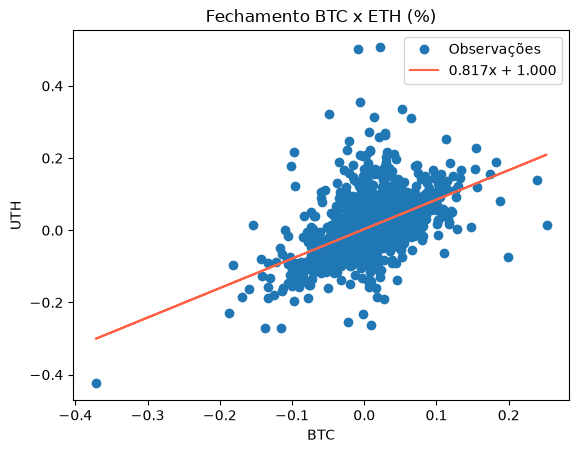

In [10]:
plt.Figure(figsize=(20,10))
plt.Figure(dpi=400)

plt.plot(df['Retorno_BTC'], df['Retorno_ETH'], 'o')
plt.plot(df['Retorno_BTC'], predict, color='tomato')

plt.title('Fechamento BTC x ETH (%)')
plt.xlabel('BTC')
plt.ylabel('UTH')
plt.legend(['Observações', f'{a:.3f}x + {b:.3f}'])